# Preliminaries

## Data Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
from sklearn.exceptions import ConvergenceWarning

# Ignore only ConvergenceWarning (not all warnings)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/09 Gallstone/gallstone.csv')
df.head()

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


In [4]:
df.columns

Index(['Gallstone Status', 'Age', 'Gender', 'Comorbidity',
       'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia',
       'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)',
       'Total Body Water (TBW)', 'Extracellular Water (ECW)',
       'Intracellular Water (ICW)',
       'Extracellular Fluid/Total Body Water (ECF/TBW)',
       'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
       'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
       'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
       'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
       'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
       'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
       'High Density Lipoprotein (HDL)', 'Triglyceride',
       'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
       'Alkaline Phosphatase (ALP)', 'Creatinine',
       'Glomerular Filtration Rate (GFR

In [5]:
numerical_columns = numerical_columns = [
    'Age', 'Height', 'Weight', 'Body Mass Index (BMI)',
    'Total Body Water (TBW)', 'Extracellular Water (ECW)',
    'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
    'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
    'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
    'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
    'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
    'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
    'High Density Lipoprotein (HDL)', 'Triglyceride',
    'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
    'Alkaline Phosphatase (ALP)', 'Creatinine',
    'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)',
    'Hemoglobin (HGB)', 'Vitamin D'
]


## Preprocessing

In [6]:
df['Gallstone Status']

,Gallstone Status
0,0
1,0
2,0
3,0
4,0
...,...
314,1
315,1
316,1
317,1


In [7]:
X = df.drop(['Gallstone Status'], axis=1)
y = df['Gallstone Status']

In [8]:
display(y.value_counts())

,count
Gallstone Status,
0,161
1,158


### Class Distribution

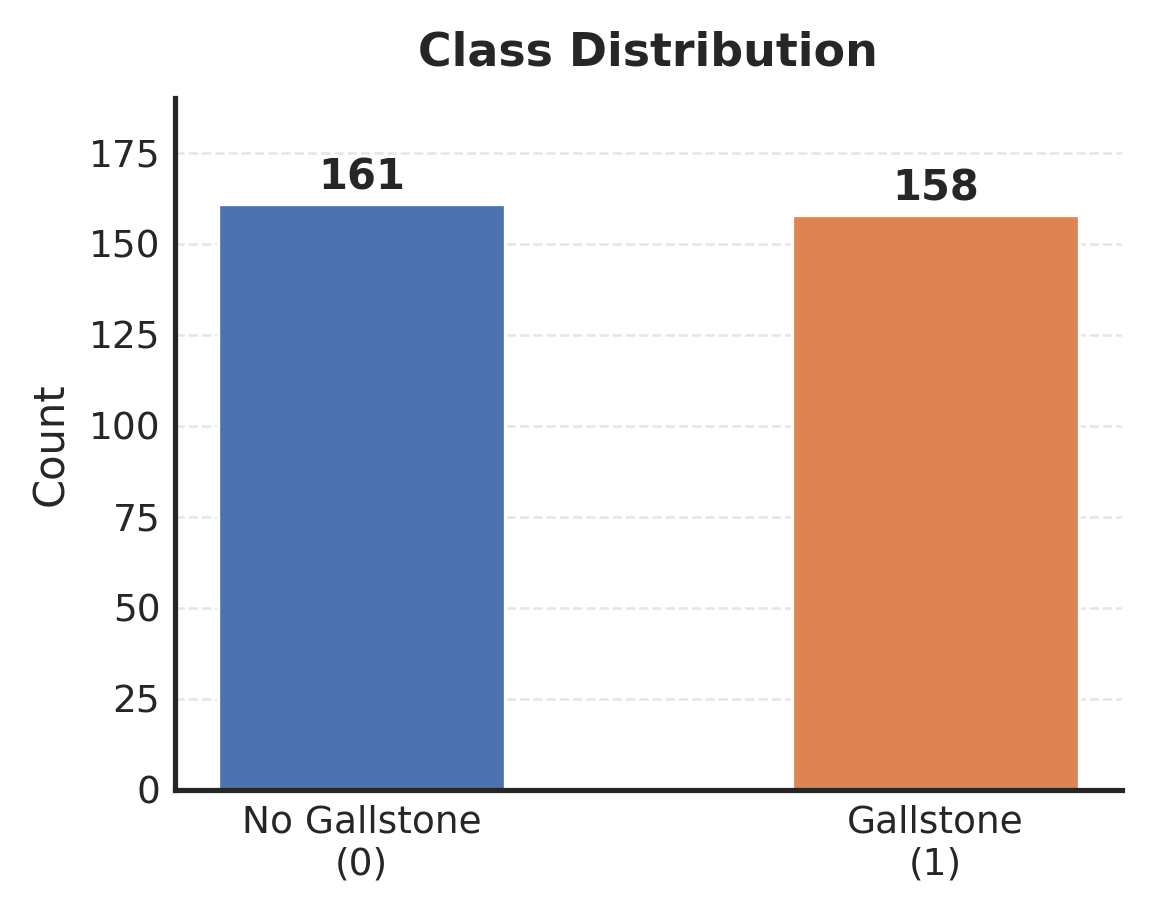

In [9]:
sns.set_theme(style="white", font_scale=1.0)

fig, ax = plt.subplots(figsize=(4, 3.2), dpi=300)

counts = y.value_counts().sort_index()
labels = ["No Gallstone\n(0)", "Gallstone\n(1)"]
colors = ["#4C72B0", "#DD8452"]

bars = ax.bar(labels, counts.values, color=colors, width=0.5, edgecolor="white", linewidth=0.8)

for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
            str(val), ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_ylabel("Count", fontsize=10)
ax.set_title("Class Distribution", fontsize=11, fontweight="bold", pad=8)
ax.set_ylim(0, max(counts.values) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="both", length=0, labelsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, linewidth=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

### Train Test Split

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
X_train_df = pd.DataFrame(X_train, columns=X.columns)
X_test_df = pd.DataFrame(X_test, columns=X.columns)

In [12]:
X_train_df.head()

,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,Body Mass Index (BMI),...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
210,39,1,1,0,0,0,0,165,74.0,27.2,...,63.0,94.0,19.0,19.0,49.0,0.58,117.90,0.00,11.9,9.500
76,20,0,0,0,0,0,0,188,62.8,17.8,...,60.0,52.0,25.0,7.0,7.0,0.93,117.75,0.00,16.0,19.625
94,49,1,1,0,1,0,0,158,92.5,37.1,...,57.0,82.0,18.0,18.0,92.0,0.63,109.77,0.78,10.7,21.800
222,31,1,0,0,0,0,0,158,100.8,40.4,...,48.0,116.0,17.0,18.0,106.0,0.72,114.50,7.00,12.2,24.000
311,47,1,0,0,0,0,0,158,63.6,25.5,...,47.0,67.0,16.0,17.0,75.0,0.59,118.20,0.15,13.9,15.700


### Log Transform

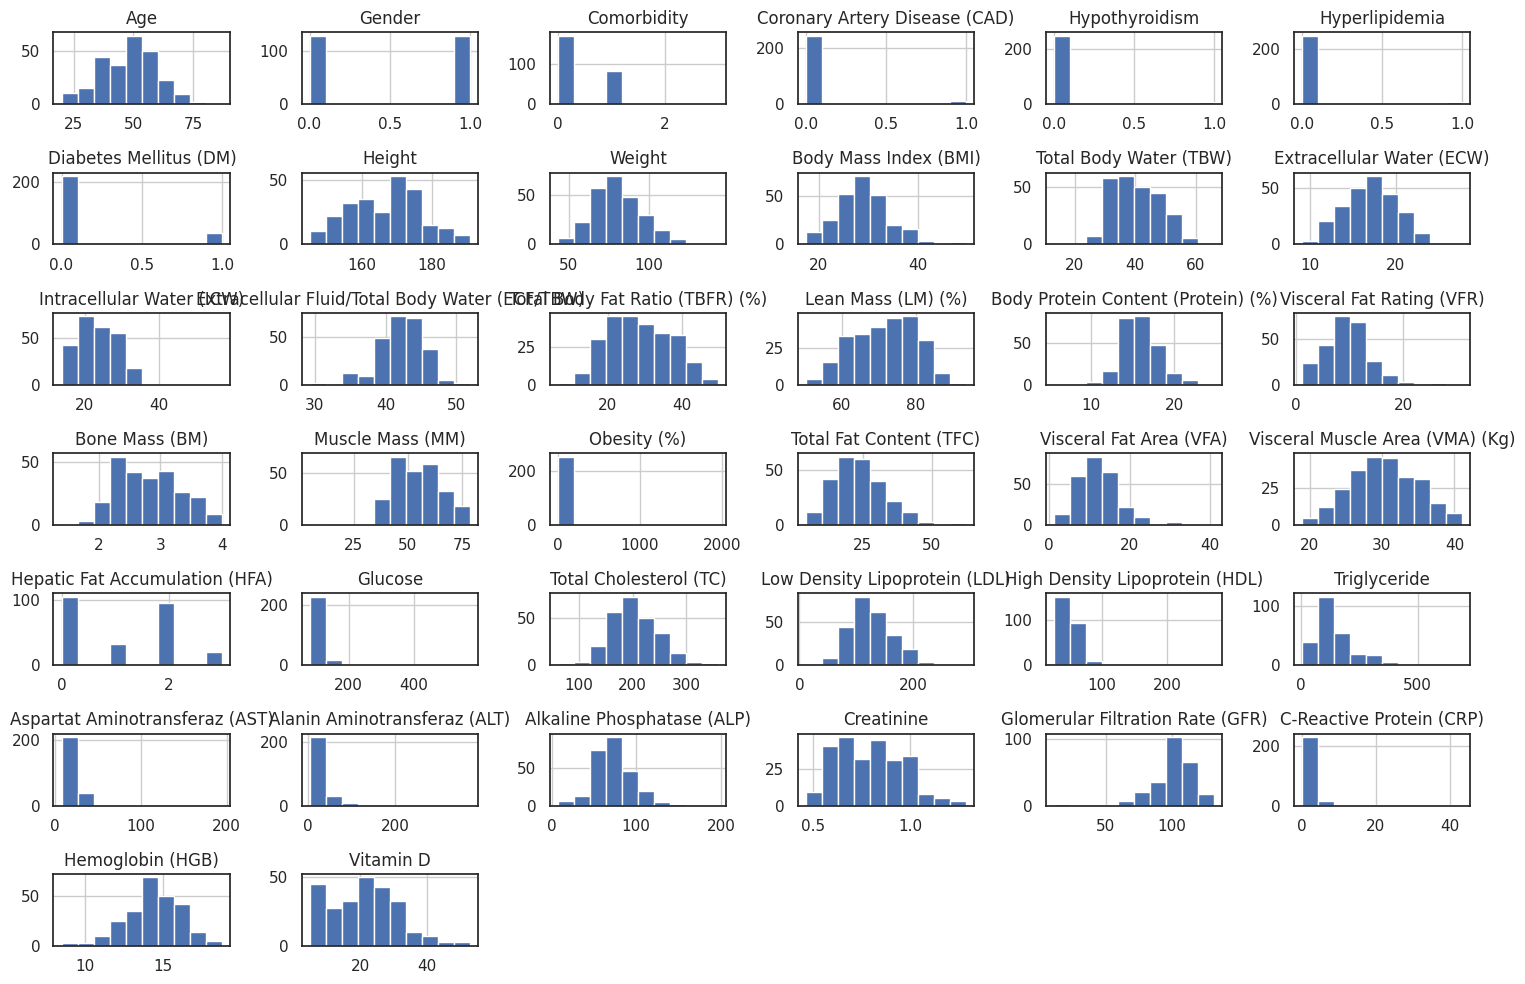

In [13]:
# Draw histograms for each feature in X_train_df
X_train_df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import skew

# Identify numerical columns (assuming they are all in X_train_df)
numerical_cols_df = X_train_df.select_dtypes(include=np.number).columns

# Calculate skewness for numerical features in the training data
skewness = X_train_df[numerical_cols_df].apply(lambda x: skew(x.dropna()))

# Define a skewness threshold
skewness_threshold = 0.4

# Identify skewed features
skewed_features = skewness[abs(skewness) > skewness_threshold].index

# Apply log transformation to skewed features in both training and testing data
for feature in skewed_features:
    # Add 1 to the feature values before taking the log to handle zero values
    X_train_df[feature] = np.log1p(X_train_df[feature])
    X_test_df[feature] = np.log1p(X_test_df[feature])

print(f"Applied log transformation to the following skewed features (skewness threshold > {skewness_threshold}):")
print(list(skewed_features))

Applied log transformation to the following skewed features (skewness threshold > 0.4):
['Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Weight', 'Body Mass Index (BMI)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Visceral Fat Rating (VFR)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)']


### Skewness Distribution

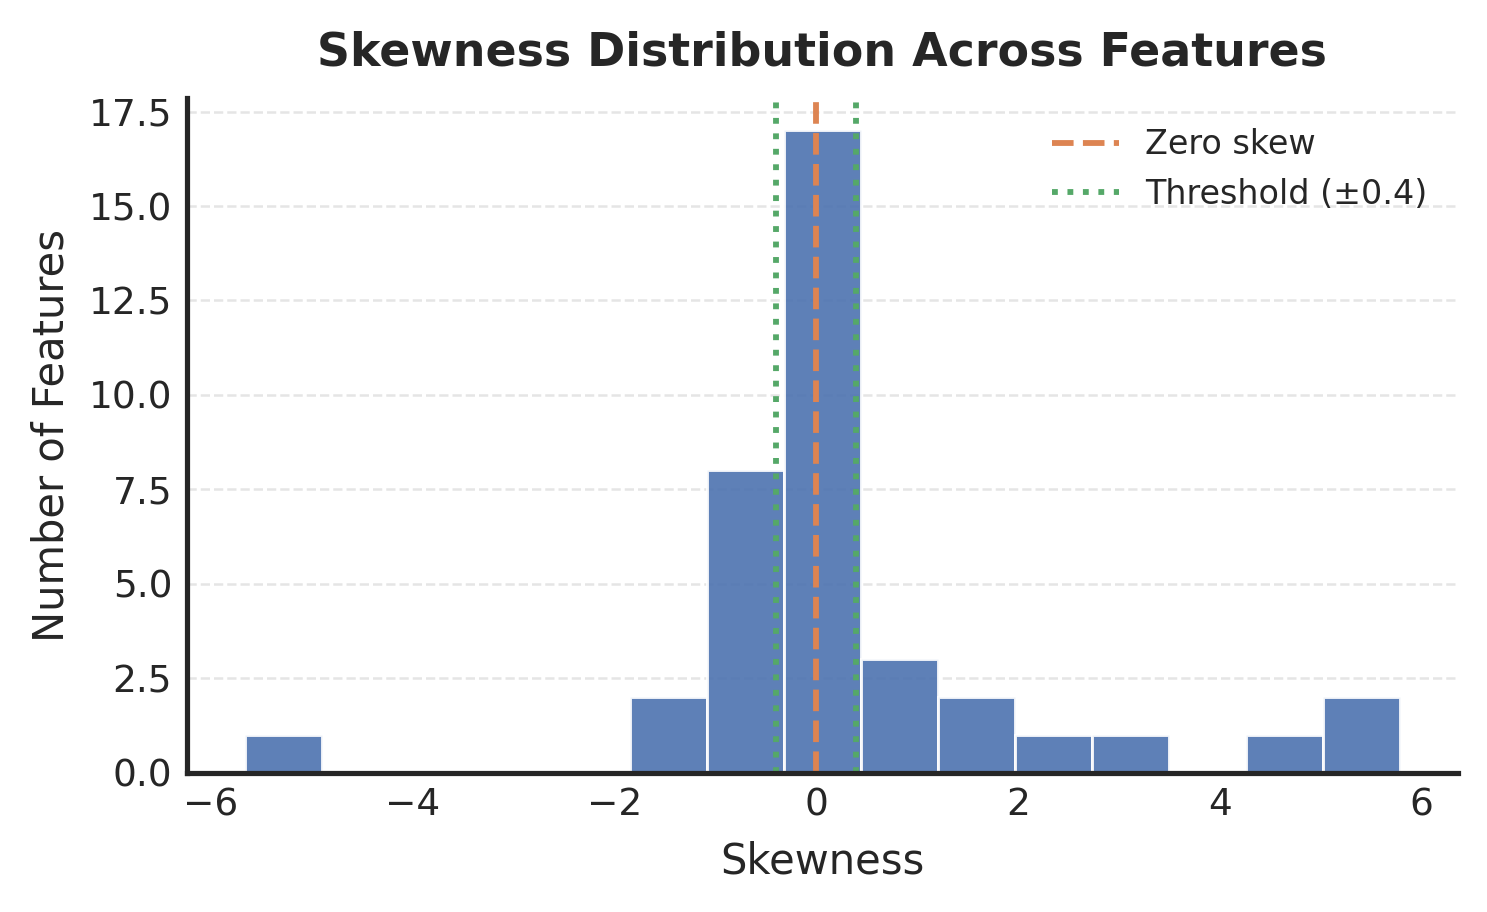

In [15]:
from scipy.stats import skew

skewness_vals = X_train_df.select_dtypes(include=np.number).apply(lambda x: skew(x.dropna()))

fig, ax = plt.subplots(figsize=(5, 3.2), dpi=300)

ax.hist(skewness_vals, bins=15, color="#4C72B0", edgecolor="white", linewidth=0.7, alpha=0.9)
ax.axvline(0, color="#DD8452", linestyle="--", linewidth=1.4, label="Zero skew")
ax.axvline(0.4, color="#55A868", linestyle=":", linewidth=1.4, label="Threshold (±0.4)")
ax.axvline(-0.4, color="#55A868", linestyle=":", linewidth=1.4)

ax.set_xlabel("Skewness", fontsize=10)
ax.set_ylabel("Number of Features", fontsize=10)
ax.set_title("Skewness Distribution Across Features", fontsize=11, fontweight="bold", pad=8)
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="both", length=0, labelsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, linewidth=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("skewness_distribution.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

### Scaling

In [16]:
from sklearn.preprocessing import StandardScaler

scaler_log = StandardScaler()
X_train_scaled_log = scaler_log.fit_transform(X_train_df)
X_test_scaled_log = scaler_log.transform(X_test_df)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_log = pd.DataFrame(X_train_scaled_log, columns=X.columns)
X_test_scaled_log = pd.DataFrame(X_test_scaled_log, columns=X.columns)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

### Removing Correlation

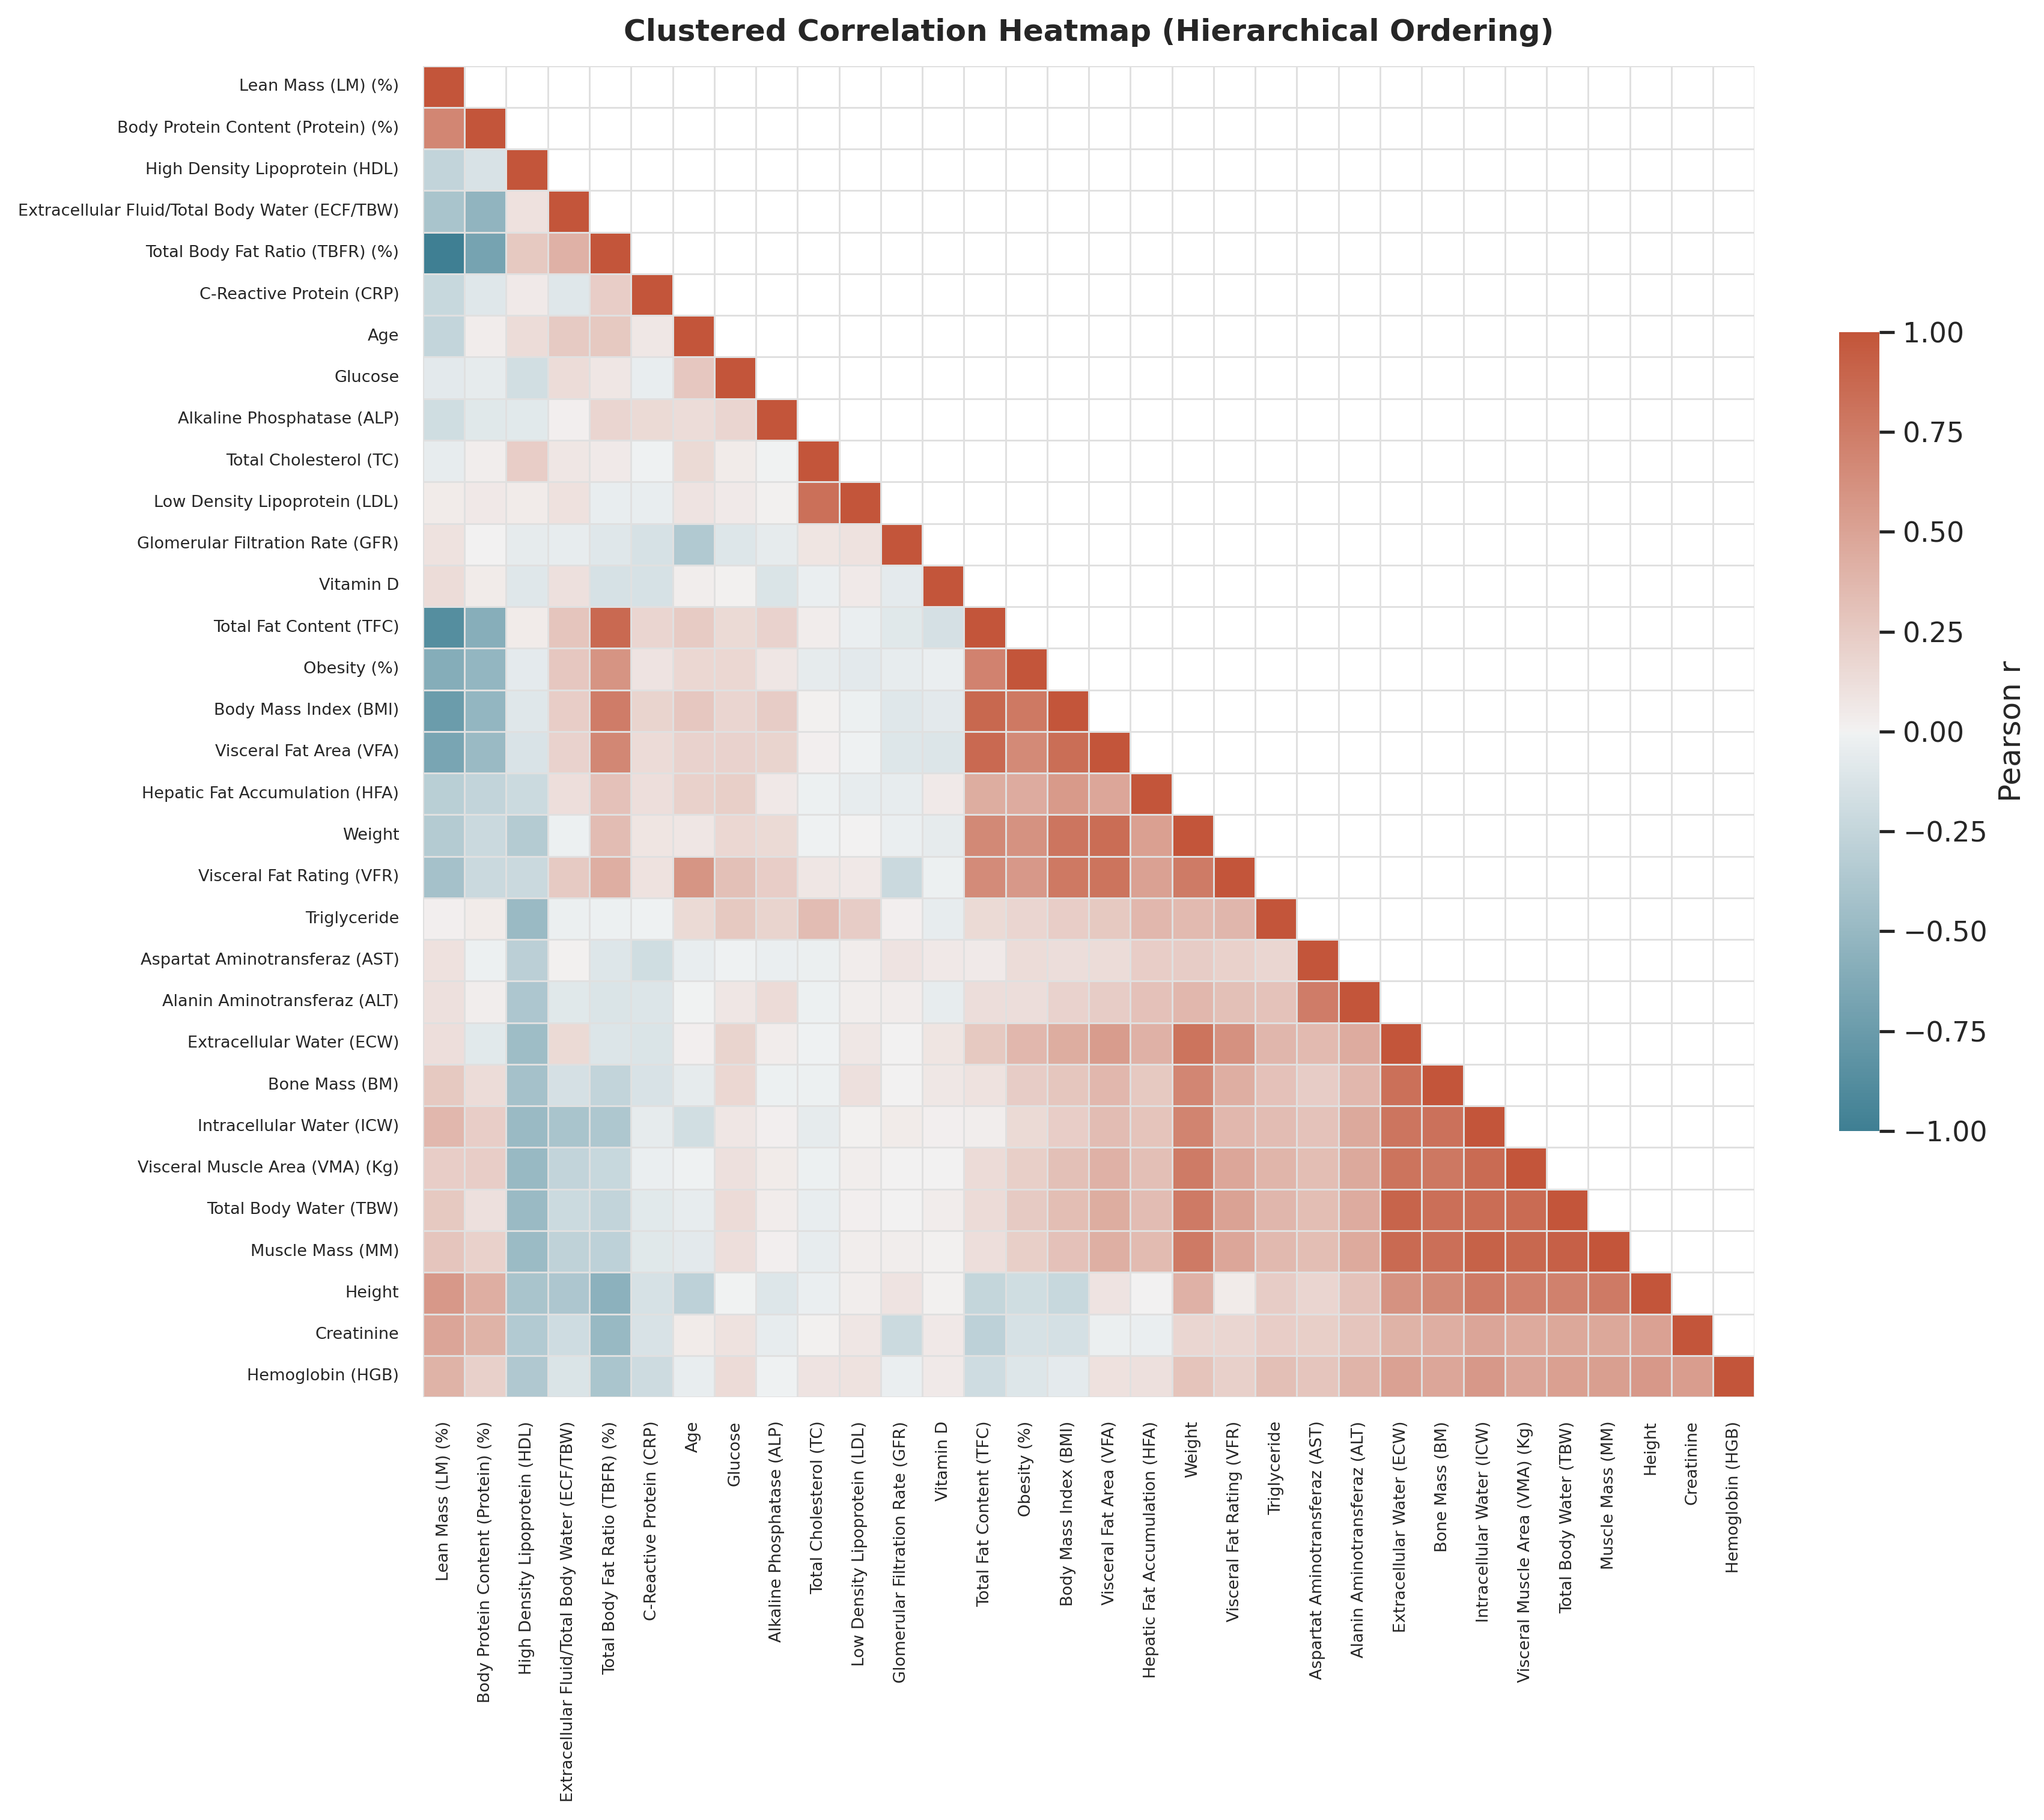

In [17]:
import scipy.cluster.hierarchy as sch
from matplotlib.patches import Rectangle

corr_matrix = X_train_scaled_log[numerical_columns].corr()

linkage = sch.linkage(corr_matrix, method="average", metric="euclidean")
order = sch.leaves_list(linkage)
corr_ordered = corr_matrix.iloc[order, :].iloc[:, order]

fig, ax = plt.subplots(figsize=(12, 10), dpi=300)

mask = np.zeros_like(corr_ordered, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True

cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(
    corr_ordered,
    mask=mask,
    cmap=cmap,
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.3,
    linecolor="#e0e0e0",
    square=True,
    cbar_kws={"shrink": 0.6, "label": "Pearson r"},
    ax=ax
)

ax.set_title("Clustered Correlation Heatmap (Hierarchical Ordering)", fontsize=12, fontweight="bold", pad=10)
ax.tick_params(axis="x", rotation=90, labelsize=6.5)
ax.tick_params(axis="y", rotation=0, labelsize=6.5)

plt.tight_layout()
plt.savefig("correlation_clustered_heatmap.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

def remove_highly_correlated_features(X_train_scaled, X_test_scaled, numerical_columns, threshold=0.8, plot=True):
    """
    Removes highly correlated features from the training and test datasets.

    Parameters:
        X_train_scaled (pd.DataFrame): Scaled training dataset.
        X_test_scaled (pd.DataFrame): Scaled test dataset.
        numerical_columns (list): List of numerical feature names.
        threshold (float): Correlation threshold for removing features. Default is 0.8.
        plot (bool): Whether to display a correlation heatmap. Default is True.

    Returns:
        X_train_uncor (pd.DataFrame): Training dataset with uncorrelated features.
        X_test_uncor (pd.DataFrame): Test dataset with uncorrelated features.
    """

    # Calculate the correlation matrix
    correlation_matrix = X_train_scaled[numerical_columns].corr()

    # Plot correlation heatmap
    if plot:
        plt.figure(figsize=(20, 16))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
        plt.title('Correlation Matrix of Numerical Features')
        plt.tight_layout()
        plt.show()

    # Find highly correlated pairs
    high_corr_pairs = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i):
            corr_value = correlation_matrix.iloc[i, j]
            if abs(corr_value) > threshold:
                col_i = correlation_matrix.columns[i]
                col_j = correlation_matrix.columns[j]
                high_corr_pairs.append((col_i, col_j, corr_value))

    # Print results
    if high_corr_pairs:
        print(f"Highly correlated feature pairs (|corr| > {threshold}):")
        for pair in high_corr_pairs:
            print(f"{pair[0]} - {pair[1]}: {pair[2]:.2f}")
    else:
        print(f"No feature pairs found with |corr| > {threshold}.")

    # Determine features to drop (drop the second feature in each pair)
    features_to_drop = {pair[1] for pair in high_corr_pairs}

    # Remove correlated features
    X_train_uncor = X_train_scaled.drop(columns=features_to_drop, errors='ignore')
    X_test_uncor = X_test_scaled.drop(columns=features_to_drop, errors='ignore')

    print(f"\nOriginal number of features: {X_train_scaled.shape[1]}")
    print(f"Number of features after dropping highly correlated: {X_train_uncor.shape[1]}")

    return X_train_uncor, X_test_uncor


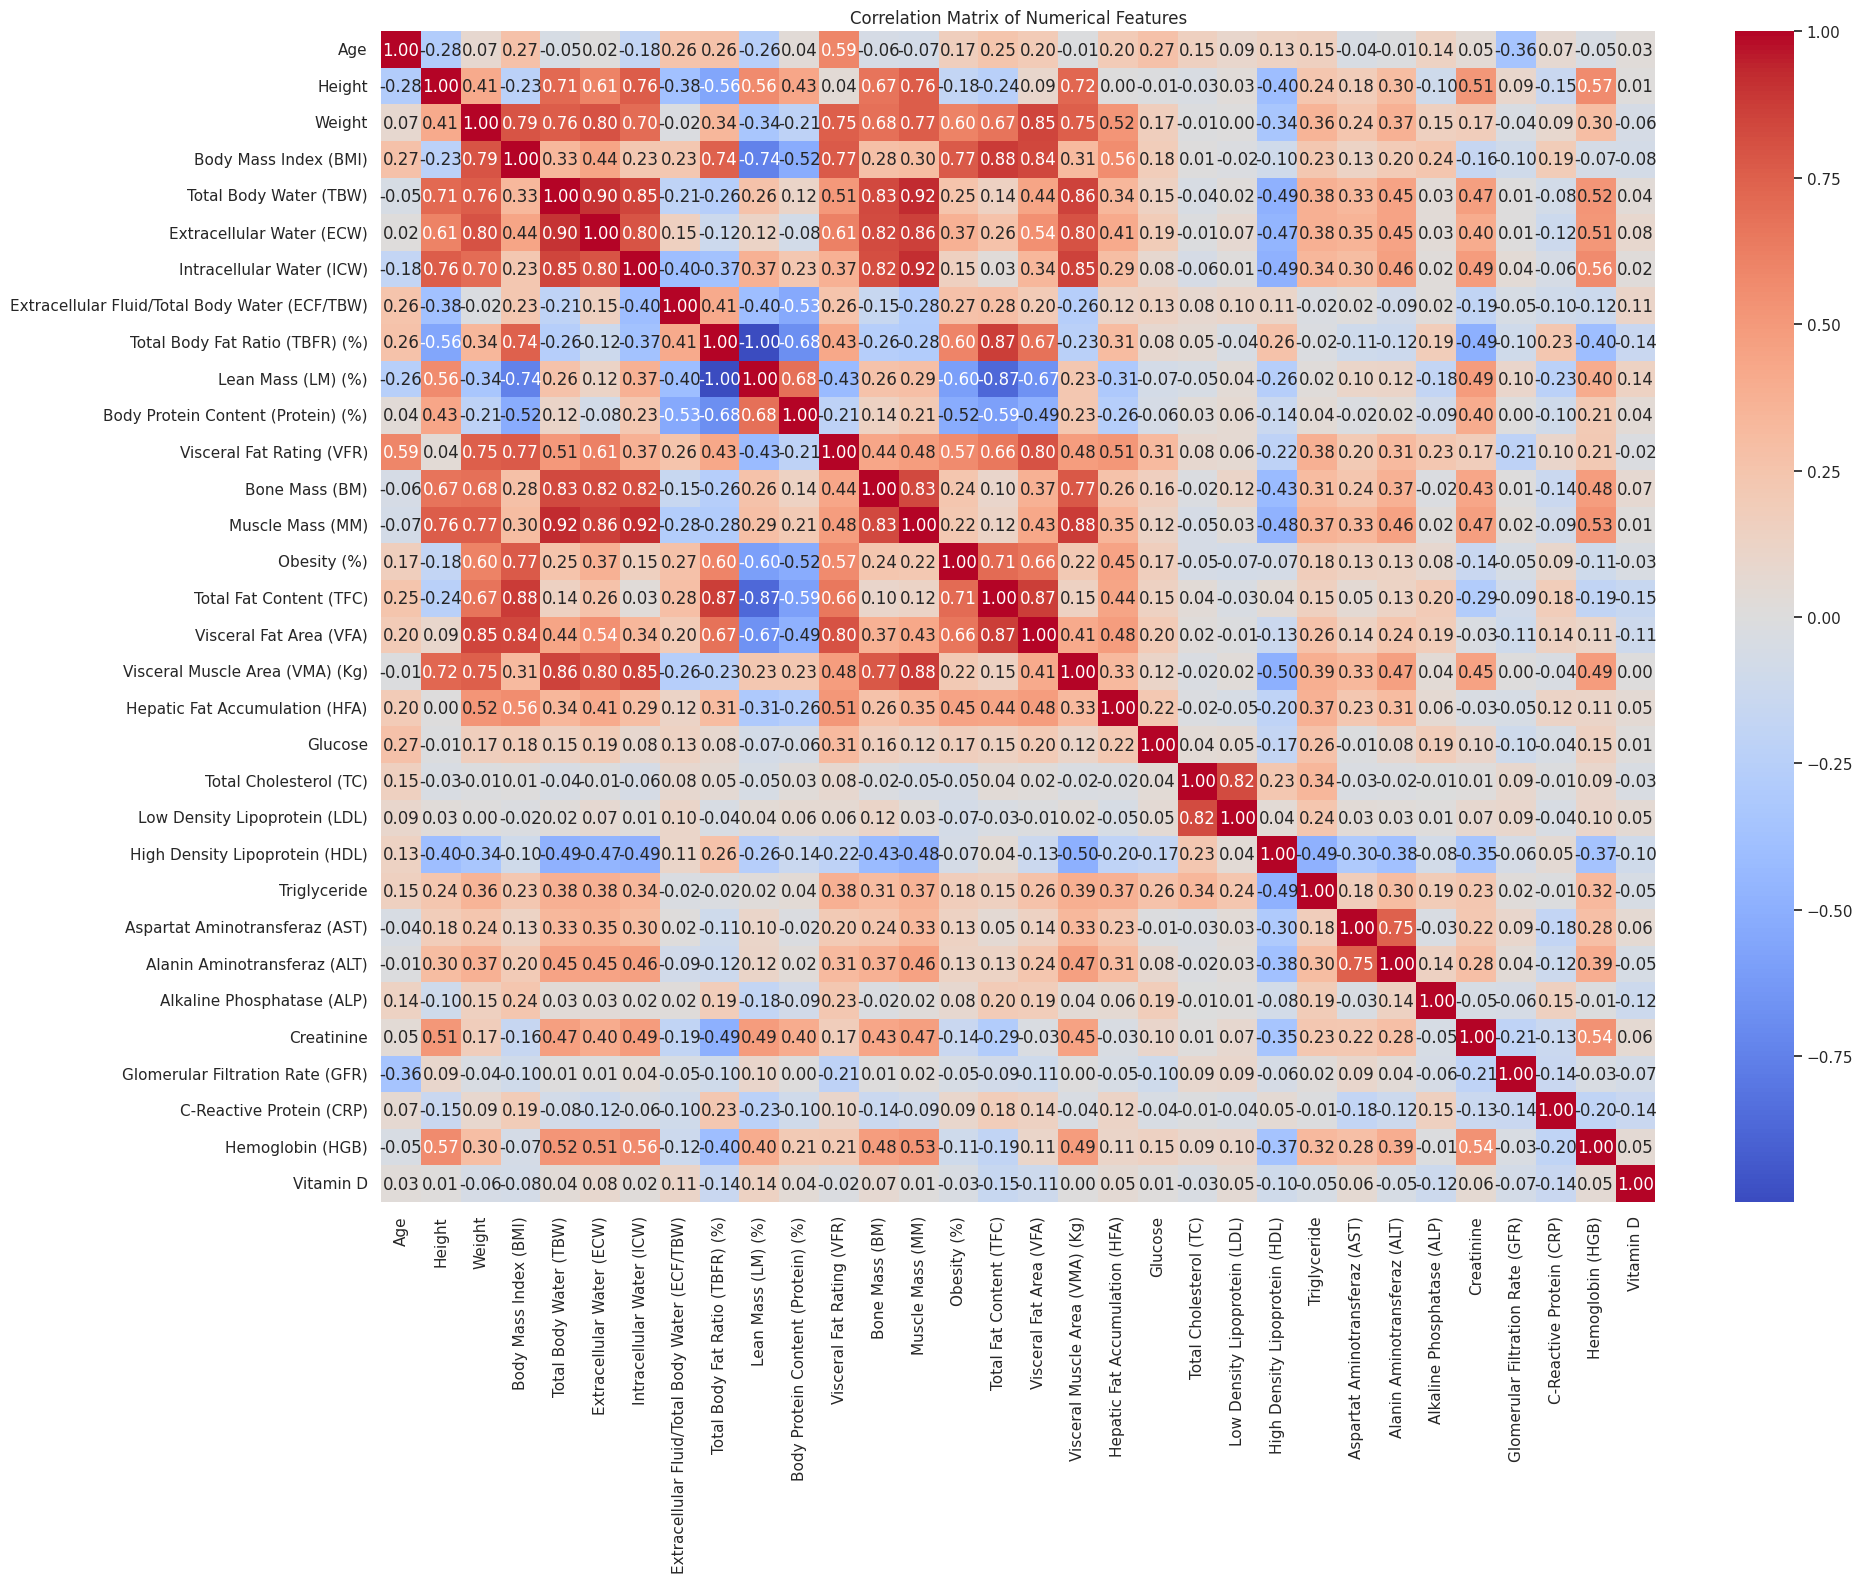

Highly correlated feature pairs (|corr| > 0.9):
Extracellular Water (ECW) - Total Body Water (TBW): 0.90
Lean Mass (LM) (%) - Total Body Fat Ratio (TBFR) (%): -1.00
Muscle Mass (MM) - Total Body Water (TBW): 0.92
Muscle Mass (MM) - Intracellular Water (ICW): 0.92

Original number of features: 38
Number of features after dropping highly correlated: 35


In [19]:
# Removing correlation from log transformed data
X_train_log_uncor, X_test_log_uncor = remove_highly_correlated_features(X_train_scaled_log, X_test_scaled_log, numerical_columns, threshold=0.9, plot=True)

## Selecting Data for Classification

In [20]:
X_tr = X_train_log_uncor.values
y_tr = y_train

X_te = X_test_log_uncor.values
y_te = y_test

# Modules

In [21]:
from sklearn.metrics import classification_report

def classification_report_row(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, output_dict=True)
    accuracy = report['accuracy']

    if '0' in report and '1' in report:
        # Extract metrics for class 0
        negative_class_metrics = report['0']
        precision_0 = negative_class_metrics['precision']
        recall_0 = negative_class_metrics['recall']
        f1_score_0 = negative_class_metrics['f1-score']
        # Extract metrics for class 1 (positive class)
        positive_class_metrics = report['1']
        precision_1 = positive_class_metrics['precision']
        recall_1 = positive_class_metrics['recall']
        f1_score_1 = positive_class_metrics['f1-score']

        return f"{model_name:<25} | Accuracy: {accuracy:.4f} | Precision (0): {precision_0:.4f} | Recall (0): {recall_0:.4f} | F1-score (0): {f1_score_0:.4f} | Precision (1): {precision_1:.4f} | Recall (1): {recall_1:.4f} | F1-score (1): {f1_score_1:.4f}"
    else:
        # Handle non-binary classification
        macro_avg = report['macro avg']
        weighted_avg = report['weighted avg']
        precision_macro = macro_avg['precision']
        recall_macro = macro_avg['recall']
        f1_score_macro = macro_avg['f1-score']
        precision_weighted = weighted_avg['precision']
        recall_weighted = weighted_avg['recall']
        f1_score_weighted = weighted_avg['f1-score']

        return (f"{model_name:<25} | Accuracy: {accuracy:.4f} | "
                f"Macro Avg Precision: {precision_macro:.4f} | Macro Avg Recall: {recall_macro:.4f} | Macro Avg F1-score: {f1_score_macro:.4f} | "
                f"Weighted Avg Precision: {precision_weighted:.4f} | Weighted Avg Recall: {recall_weighted:.4f} | Weighted Avg F1-score: {f1_score_weighted:.4f}")


def classification_report_header():
    return f"{'Model Name':<25} | Accuracy | Precision (0) | Recall (0) | F1-score (0) | Precision (1) | Recall (1) | F1-score (1)"

def classification_report_header_non_binary():
     return f"{'Model Name':<25} | Accuracy | Macro Avg Precision | Macro Avg Recall | Macro Avg F1-score | Weighted Avg Precision | Weighted Avg Recall | Weighted Avg F1-score"

In [22]:
def variance_plot(df, columns, figsize=(12, 6), xticks_rotation=90):
    """
    Plots the variance of specified columns in a DataFrame and shows the variance value above each bar.

    Args:
        df (pd.DataFrame): The input DataFrame.
        columns (list): A list of column names to calculate and plot variance for.
        figsize (tuple, optional): The size of the figure. Defaults to (12, 6).
        xticks_rotation (int, optional): The rotation angle for x-axis labels. Defaults to 90.
    """
    # Calculate variance for specified columns
    variance = df[columns].var().sort_values(ascending=False)

    # Plot the variance
    plt.figure(figsize=figsize)
    ax = sns.barplot(x=variance.index, y=variance.values)

    # Update x-axis labels to include variance values
    ax.set_xticklabels([f"{col} ({variance[col]:.2f})" for col in variance.index], rotation=xticks_rotation)

    plt.xlabel('Features (Variance)')
    plt.ylabel('Variance')
    plt.title('Variance of Each Feature (Sorted)')
    plt.tight_layout()
    plt.show()

# Classification - Conventional

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [28]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='lbfgs', max_iter=100),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'XGBoost': XGBClassifier(random_state=42),
    'Neural Network': MLPClassifier(random_state=42)
}

In [29]:
outputs = {
    'Logistic Regression': [],
    'Decision Tree': [],
    'Random Forest': [],
    'Gradient Boosting': [],
    'AdaBoost': [],
    'Support Vector Machine': [],
    'K-Nearest Neighbors': [],
    'Naive Bayes': [],
    'XGBoost': [],
    'Neural Network': []
}

## Model Train

In [30]:
for name, model in models.items():
    model.fit(X_tr, y_tr)
    prediction = model.predict(X_te)
    outputs[name].append(prediction)
    print(classification_report_row(name, y_test, prediction))
    print( confusion_matrix(y_test, prediction))

Logistic Regression       | Accuracy: 0.8750 | Precision (0): 0.8571 | Recall (0): 0.9091 | F1-score (0): 0.8824 | Precision (1): 0.8966 | Recall (1): 0.8387 | F1-score (1): 0.8667
[[30  3]
 [ 5 26]]
Decision Tree             | Accuracy: 0.7500 | Precision (0): 0.7429 | Recall (0): 0.7879 | F1-score (0): 0.7647 | Precision (1): 0.7586 | Recall (1): 0.7097 | F1-score (1): 0.7333
[[26  7]
 [ 9 22]]
Random Forest             | Accuracy: 0.8438 | Precision (0): 0.8485 | Recall (0): 0.8485 | F1-score (0): 0.8485 | Precision (1): 0.8387 | Recall (1): 0.8387 | F1-score (1): 0.8387
[[28  5]
 [ 5 26]]
Gradient Boosting         | Accuracy: 0.8750 | Precision (0): 0.8788 | Recall (0): 0.8788 | F1-score (0): 0.8788 | Precision (1): 0.8710 | Recall (1): 0.8710 | F1-score (1): 0.8710
[[29  4]
 [ 4 27]]
AdaBoost                  | Accuracy: 0.7969 | Precision (0): 0.7778 | Recall (0): 0.8485 | F1-score (0): 0.8116 | Precision (1): 0.8214 | Recall (1): 0.7419 | F1-score (1): 0.7797
[[28  5]
 [ 8 23]]


In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_results = {}

print("Training models with 3-fold cross-validation...")
for name, model in models.items():
    # Use StratifiedKFold for classification tasks to preserve class balance
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Perform cross-validation and get accuracy scores
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy', n_jobs=-1)

    cv_results[name] = scores

    print(f"{name:<25} | Mean CV Accuracy: {scores.mean():.4f} | Std Dev: {scores.std():.4f}")

print("\nCross-validation complete.")

Training models with 3-fold cross-validation...
Logistic Regression       | Mean CV Accuracy: 0.7804 | Std Dev: 0.0649
Decision Tree             | Mean CV Accuracy: 0.6431 | Std Dev: 0.0517
Random Forest             | Mean CV Accuracy: 0.7451 | Std Dev: 0.0555
Gradient Boosting         | Mean CV Accuracy: 0.7255 | Std Dev: 0.0702
AdaBoost                  | Mean CV Accuracy: 0.7098 | Std Dev: 0.1033
Support Vector Machine    | Mean CV Accuracy: 0.7608 | Std Dev: 0.0192
K-Nearest Neighbors       | Mean CV Accuracy: 0.6549 | Std Dev: 0.0457
Naive Bayes               | Mean CV Accuracy: 0.5608 | Std Dev: 0.0342
XGBoost                   | Mean CV Accuracy: 0.7412 | Std Dev: 0.0288
Neural Network            | Mean CV Accuracy: 0.7804 | Std Dev: 0.0532

Cross-validation complete.


## Hyperparameter Tuning using XGBoost

In [32]:
# Install optuna and xgboost if not present
try:
    import optuna
except ImportError:
    import sys
    !{sys.executable} -m pip install optuna -q
    import optuna

try:
    import xgboost as xgb
except ImportError:
    import sys
    !{sys.executable} -m pip install xgboost -q
    import xgboost as xgb

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define the objective function for Optuna
def objective(trial):
    # Hyperparameters to tune
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 42,
        'n_jobs': -1,
        'eval_metric': 'logloss'
    }

    # Define model
    model = xgb.XGBClassifier(**param)

    # Stratified 3-fold cross-validation (for recall)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy')

    return scores.mean()

# Create and run Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# Display results
print("Best hyperparameters:", study.best_params)
print("Best recall:", study.best_value)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 7.6 MB/s eta 0:00:00


[I 2026-05-22 15:13:29,451] A new study created in memory with name: no-name-09303257-16fc-4ef2-8b1a-1e9f5ee56fbc


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-05-22 15:13:29,739] Trial 0 finished with value: 0.788235294117647 and parameters: {'n_estimators': 410, 'max_depth': 13, 'learning_rate': 0.03140618446941822, 'subsample': 0.800193412297209, 'colsample_bytree': 0.9274606286333894, 'gamma': 2.3113420241549405, 'reg_alpha': 0.0025221268677414043, 'reg_lambda': 0.000533042028378456, 'min_child_weight': 7}. Best is trial 0 with value: 0.788235294117647.
[I 2026-05-22 15:13:30,184] Trial 1 finished with value: 0.7803921568627451 and parameters: {'n_estimators': 704, 'max_depth': 6, 'learning_rate': 0.01242672359629432, 'subsample': 0.5282591240090591, 'colsample_bytree': 0.5906064239052371, 'gamma': 1.3897966511054383, 'reg_alpha': 0.0009128018952462971, 'reg_lambda': 0.0016016428295588384, 'min_child_weight': 5}. Best is trial 0 with value: 0.788235294117647.
[I 2026-05-22 15:13:30,526] Trial 2 finished with value: 0.7803921568627451 and parameters: {'n_estimators': 601, 'max_depth': 13, 'learning_rate': 0.05131140205294439, 'subs

In [33]:
xgbc = xgb.XGBClassifier(**study.best_params)
xgbc.fit(X_tr, y_tr)

prediction = xgbc.predict(X_te)
print(classification_report_row('XGBoost', y_test, prediction))

XGBoost                   | Accuracy: 0.8906 | Precision (0): 0.8824 | Recall (0): 0.9091 | F1-score (0): 0.8955 | Precision (1): 0.9000 | Recall (1): 0.8710 | F1-score (1): 0.8852


## Voting Classifier

In [34]:
from sklearn.ensemble import VotingClassifier
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.validation import check_is_fitted
import numpy as np


class VotingModel(BaseEstimator, ClassifierMixin):
    """
    A custom sklearn-compatible voting classifier that supports:
    - Custom estimators passed as input
    - Weighted soft/hard voting
    - Probability thresholding for binary classification
    """

    def __init__(
        self,
        estimators,
        voting='soft',
        n_jobs=-1,
        threshold=0.5,
        weights=None
    ):
        """
        Parameters
        ----------
        estimators : list of (str, estimator)
            Base estimators passed to VotingClassifier.

        voting : {'soft', 'hard'}, default='soft'
            Voting type.

        n_jobs : int, default=-1
            Number of CPU cores used during training.

        threshold : float, default=0.5
            Classification threshold for soft voting.

        weights : list or None, default=None
            Model weights (must match number of estimators).
        """
        self.estimators = estimators
        self.voting = voting
        self.n_jobs = n_jobs
        self.threshold = threshold
        self.weights = weights

        self.model_ = None

    def fit(self, X, y):
        """Fit the voting classifier."""

        # Clone estimators to ensure sklearn compatibility
        estimators = [
            (name, clone(estimator))
            for name, estimator in self.estimators
        ]

        self.model_ = VotingClassifier(
            estimators=estimators,
            voting=self.voting,
            n_jobs=self.n_jobs,
            weights=self.weights
        )

        self.model_.fit(X, y)
        return self

    def predict_proba(self, X):
        """Predict class probabilities (soft voting only)."""
        check_is_fitted(self, 'model_')

        if self.voting != 'soft':
            raise AttributeError(
                "predict_proba is only available when voting='soft'"
            )

        return self.model_.predict_proba(X)

    def predict(self, X):
        """Predict class labels."""

        check_is_fitted(self, 'model_')

        if self.voting == 'soft':
            proba = self.model_.predict_proba(X)[:, 1]
            return (proba >= self.threshold).astype(int)

        return self.model_.predict(X)

    def score(self, X, y):
        """Return mean accuracy."""
        check_is_fitted(self, 'model_')

        y_pred = self.predict(X)
        return np.mean(y_pred == y)

In [35]:
# -----------------------------
# Voting Model 01
# Uses:
# - Logistic Regression
# - Gradient Boosting
# - MLP
# -----------------------------
estimators_01 = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100,), random_state=42))
]

In [36]:
import itertools
from sklearn.model_selection import StratifiedKFold, cross_val_score

def generate_weight_combinations(n_estimators, total_sum):
    return [
        list(p)
        for p in itertools.product(range(1, total_sum + 1), repeat=n_estimators)
        if sum(p) == total_sum
    ]

weight_combinations = generate_weight_combinations(
    n_estimators=len(estimators_01),
    total_sum=10
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_weights = None
best_accuracy = -1

for weights in weight_combinations:

    model = VotingModel(
        estimators=estimators_01,
        voting='hard',
        threshold=0.5,
        weights=weights
    )

    scores = cross_val_score(
        model,
        X_tr,
        y_tr,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    accuracy = scores.mean()

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_weights = weights

print(f"Best weights: {best_weights}")
print(f"Best CV accuracy: {best_accuracy:.4f}")

Best weights: [2, 4, 4]
Best CV accuracy: 0.7922


In [37]:
votingModelLGM = VotingModel(
    estimators=estimators_01,
    voting='hard',
    threshold=0.5,
    weights=best_weights
)

votingModelLGM.fit(X_tr, y_tr)

prediction = votingModelLGM.predict(X_te)

print(
    classification_report_row(
        'Voting Classifier (Optimized Weights)',
        y_test,
        prediction
    )
)

Voting Classifier (Optimized Weights) | Accuracy: 0.9219 | Precision (0): 0.9118 | Recall (0): 0.9394 | F1-score (0): 0.9254 | Precision (1): 0.9333 | Recall (1): 0.9032 | F1-score (1): 0.9180


### ROC-AUC

In [38]:
# -----------------------------
# Voting Model 02
# Uses:
# - Logistic Regression
# - XGBoost
# - MLP
# -----------------------------
estimators_02 = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('xgb', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        use_label_encoder=False
    )),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100,), random_state=42))
]

In [39]:
import itertools
from sklearn.model_selection import StratifiedKFold, cross_val_score

def generate_weight_combinations(n_estimators, total_sum):
    return [
        list(p)
        for p in itertools.product(range(1, total_sum + 1), repeat=n_estimators)
        if sum(p) == total_sum
    ]

weight_combinations = generate_weight_combinations(
    n_estimators=len(estimators_02),
    total_sum=10
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_weights = None
best_accuracy = -1

for weights in weight_combinations:

    model = VotingModel(
        estimators=estimators_02,
        voting='hard',
        threshold=0.5,
        weights=weights
    )

    scores = cross_val_score(
        model,
        X_tr,
        y_tr,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    accuracy = scores.mean()

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_weights = weights

print(f"Best weights: {best_weights}")
print(f"Best CV accuracy: {best_accuracy:.4f}")

Best weights: [2, 4, 4]
Best CV accuracy: 0.7922


In [40]:
votingModelXGB = VotingModel(
    estimators=estimators_02,
    voting='hard',
    threshold=0.5,
    weights=best_weights
)

votingModelXGB.fit(X_tr, y_tr)

prediction = votingModelXGB.predict(X_te)

print(
    classification_report_row(
        'Voting Classifier XGB (Optimized Weights)',
        y_test,
        prediction
    )
)

Voting Classifier XGB (Optimized Weights) | Accuracy: 0.9062 | Precision (0): 0.8857 | Recall (0): 0.9394 | F1-score (0): 0.9118 | Precision (1): 0.9310 | Recall (1): 0.8710 | F1-score (1): 0.9000


=== ROC-AUC Results ===
Voting LGM AUC: 0.9326
Voting LXM AUC: 0.9345


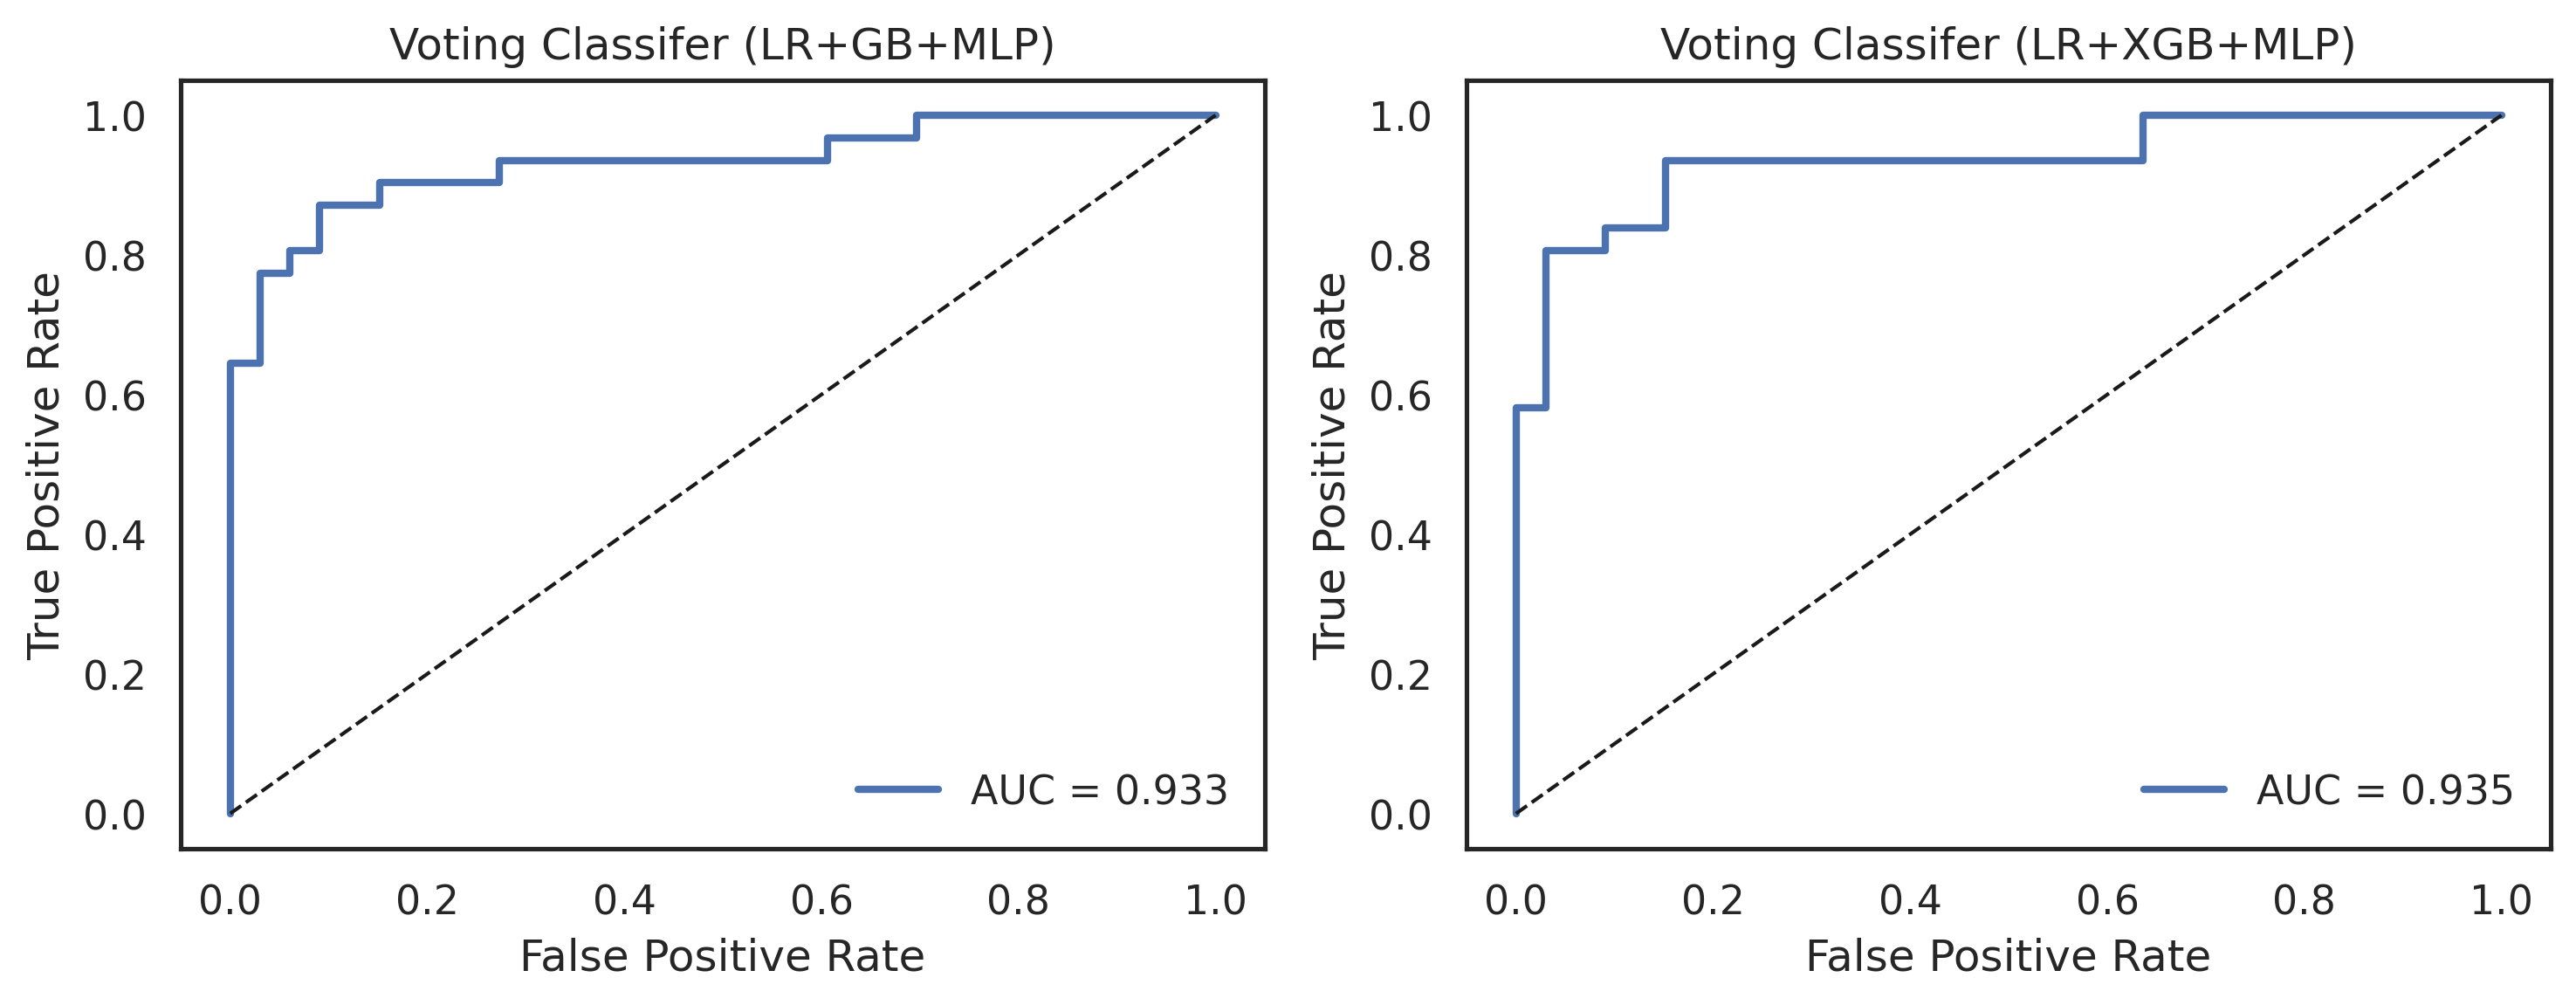

In [57]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# -----------------------------
# Model 1: Voting LGM (estimators_01)
# -----------------------------
votingModelLGM_soft = VotingModel(
    estimators=estimators_01,
    voting='soft',
    threshold=0.5,
    weights=best_weights
)

votingModelLGM_soft.fit(X_tr, y_tr)
y_score_1 = votingModelLGM_soft.predict_proba(X_te)[:, 1]

fpr1, tpr1, _ = roc_curve(y_test, y_score_1)
auc1 = auc(fpr1, tpr1)

# -----------------------------
# Model 2: Voting LXM (estimators_02)
# -----------------------------
votingModelLXM_soft = VotingModel(
    estimators=estimators_02,
    voting='soft',
    threshold=0.5,
    weights=best_weights
)

votingModelLXM_soft.fit(X_tr, y_tr)
y_score_2 = votingModelLXM_soft.predict_proba(X_te)[:, 1]

fpr2, tpr2, _ = roc_curve(y_test, y_score_2)
auc2 = auc(fpr2, tpr2)

# -----------------------------
# Print ROC-AUC values
# -----------------------------
print("=== ROC-AUC Results ===")
print(f"Voting LGM AUC: {auc1:.4f}")
print(f"Voting LXM AUC: {auc2:.4f}")

# -----------------------------
# Single figure with 2 subplots
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=300)

# --- Plot 1 ---
axes[0].plot(fpr1, tpr1, linewidth=2, label=f"AUC = {auc1:.3f}")
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_title("Voting Classifer (LR+GB+MLP)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(frameon=False)

# --- Plot 2 ---
axes[1].plot(fpr2, tpr2, linewidth=2, label=f"AUC = {auc2:.3f}")
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[1].set_title("Voting Classifer (LR+XGB+MLP)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(frameon=False)

# -----------------------------
# Clean layout
# -----------------------------
plt.tight_layout()
plt.savefig("roc_voting_side_by_side.png", dpi=300, bbox_inches="tight")
plt.show()

### Error Analysis

In [42]:
# Find misclassified indices
misclassified_indices = np.where(prediction != y_test)[0]

# Get the misclassified data from the original test set (before scaling and log transform)
# Use X_test directly as it contains the original values with column names
misclassified_data = X_test.iloc[misclassified_indices]

# Add the true and predicted labels to the misclassified data
misclassified_data['True Gallstone Status'] = y_test.iloc[misclassified_indices]
misclassified_data['Predicted Gallstone Status'] = prediction[misclassified_indices]

print("Misclassified data points:")
display(misclassified_data)

Misclassified data points:


/tmp/ipykernel_990/429329682.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  misclassified_data['True Gallstone Status'] = y_test.iloc[misclassified_indices]
/tmp/ipykernel_990/429329682.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  misclassified_data['Predicted Gallstone Status'] = prediction[misclassified_indices]


,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,Body Mass Index (BMI),...,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D,True Gallstone Status,Predicted Gallstone Status
73,44,0,0,0,0,0,0,179,81.9,25.6,...,17.0,20.0,66.0,1.03,91.83,0.63,15.5,10.900000,0,1
176,51,0,0,0,0,0,0,177,78.6,25.1,...,26.0,41.0,127.0,1.00,91.12,0.60,16.4,12.700000,1,0
177,24,0,0,0,0,0,0,165,64.0,23.5,...,21.0,20.0,73.0,0.87,123.57,0.55,16.7,23.300000,1,0
118,43,1,0,0,0,0,0,161,70.4,27.2,...,13.0,17.0,46.0,0.64,112.38,0.00,13.6,8.233333,0,1
299,59,0,0,0,0,0,0,172,78.8,26.6,...,17.0,16.0,92.0,1.24,66.90,0.20,14.5,36.900000,1,0
194,56,0,1,0,0,0,1,176,116.1,37.5,...,17.0,39.0,70.0,1.34,76.40,0.20,15.6,26.700000,1,0


### SHAP Analysis

In [43]:
!pip install shap -q

  0%|          | 0/64 [00:00<?, ?it/s]


--------------------------------------------------------------------------------
FULL SHAP VALUES: VotingModelLGM
--------------------------------------------------------------------------------
                                           feature  mean_abs_shap
0                         C-Reactive Protein (CRP)       0.151463
1                                        Vitamin D       0.083326
2                                   Bone Mass (BM)       0.070079
3   Extracellular Fluid/Total Body Water (ECF/TBW)       0.048891
4                   Aspartat Aminotransferaz (AST)       0.045525
5               Body Protein Content (Protein) (%)       0.042413
6                          Visceral Fat Area (VFA)       0.040581
7                   High Density Lipoprotein (HDL)       0.023204
8                                 Hemoglobin (HGB)       0.022746
9                                      Obesity (%)       0.016654
10                       Extracellular Water (ECW)       0.014285
11          

  0%|          | 0/64 [00:00<?, ?it/s]


--------------------------------------------------------------------------------
FULL SHAP VALUES: VotingModelXGB
--------------------------------------------------------------------------------
                                           feature  mean_abs_shap
0                         C-Reactive Protein (CRP)       0.149416
1                                        Vitamin D       0.088467
2                                   Bone Mass (BM)       0.074851
3                   Aspartat Aminotransferaz (AST)       0.050224
4   Extracellular Fluid/Total Body Water (ECF/TBW)       0.047693
5                          Visceral Fat Area (VFA)       0.046885
6               Body Protein Content (Protein) (%)       0.045335
7                                 Hemoglobin (HGB)       0.030705
8                   High Density Lipoprotein (HDL)       0.025565
9                                      Obesity (%)       0.021027
10                    Alanin Aminotransferaz (ALT)       0.013559
11          

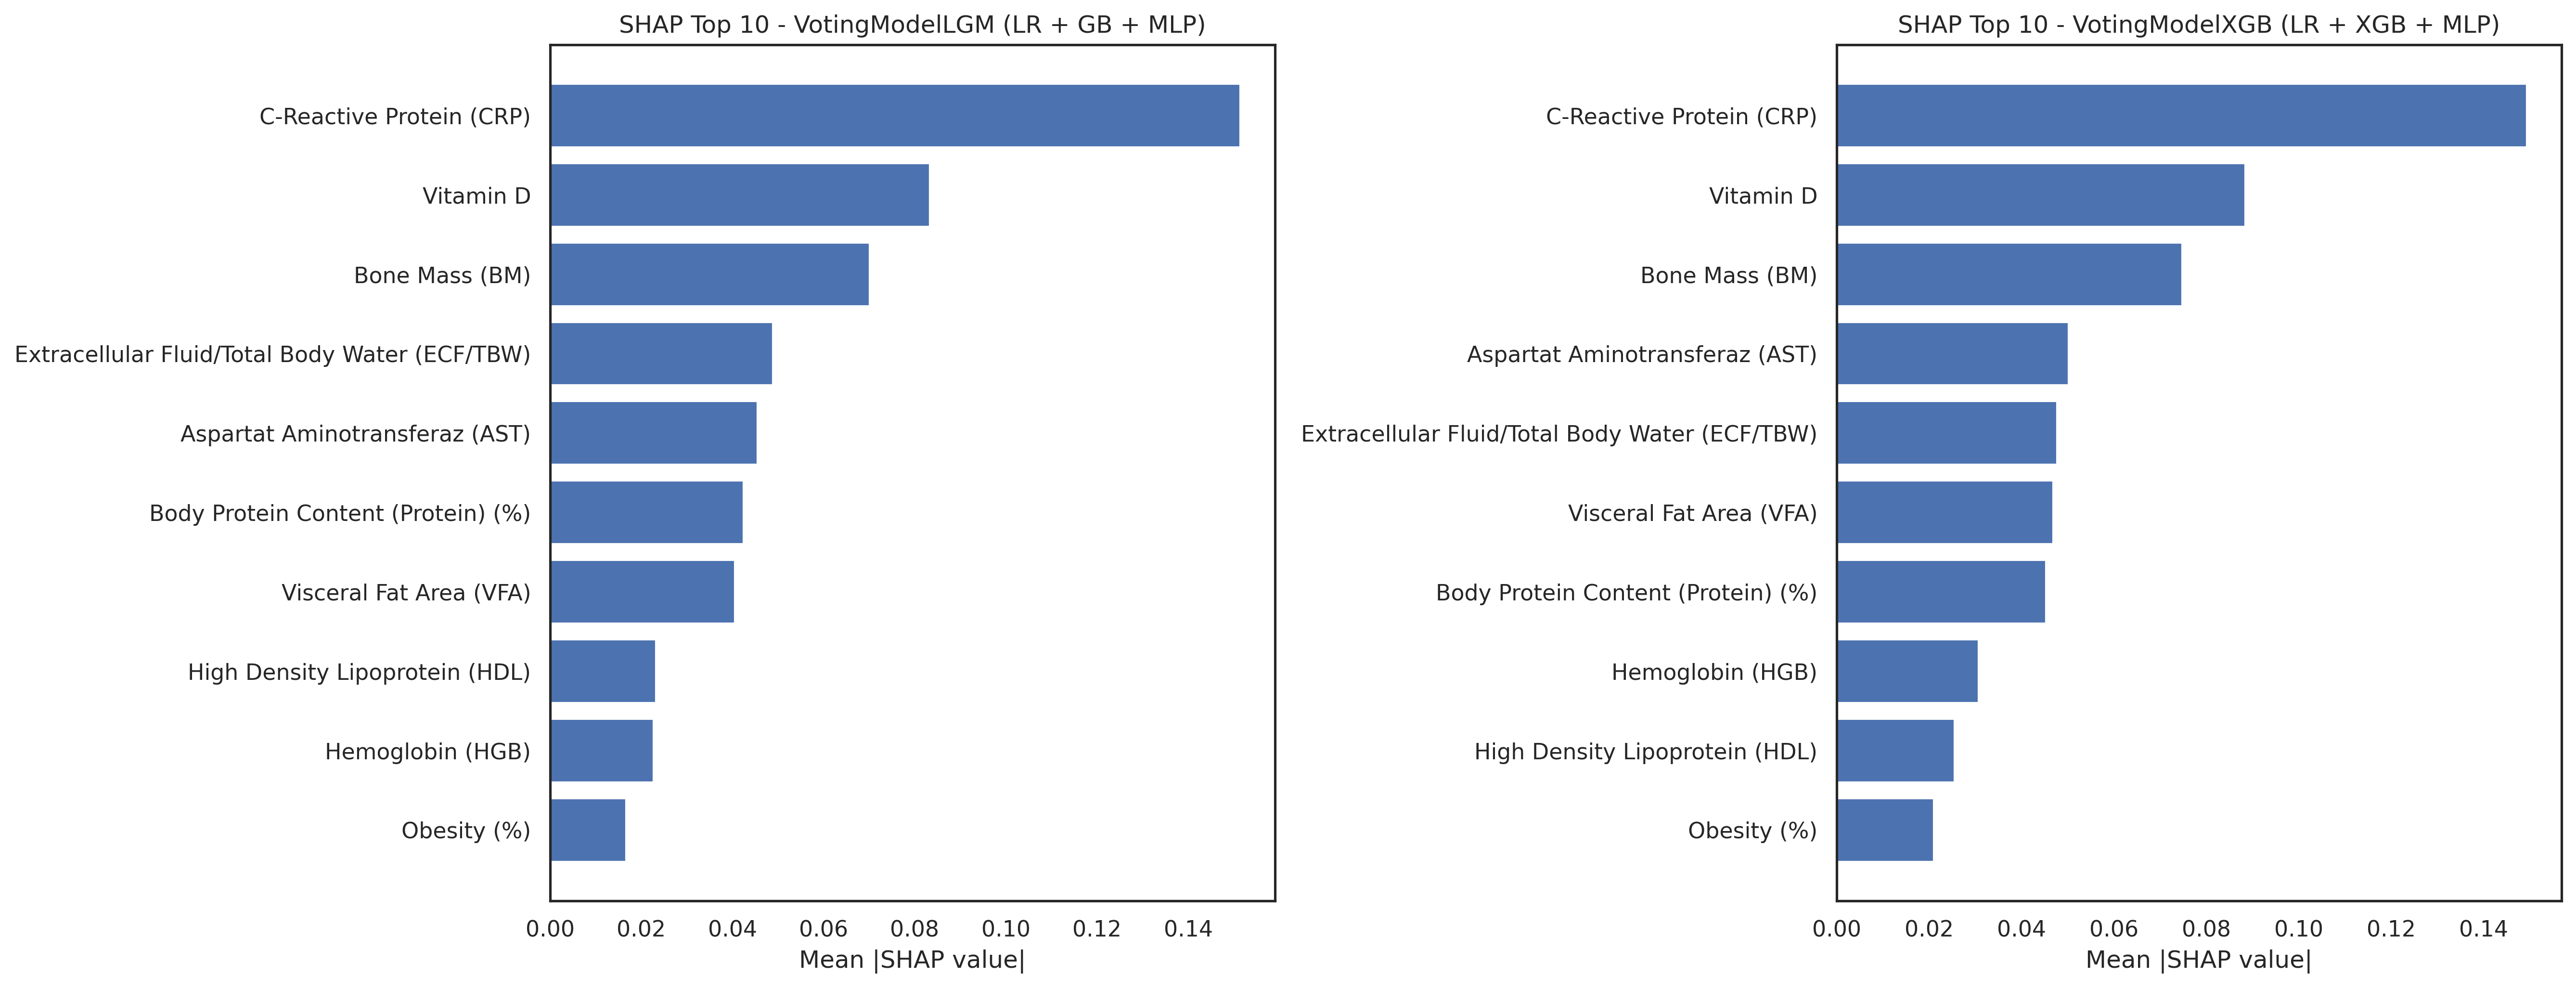

In [44]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Prepare test dataframe
X_te_df = pd.DataFrame(X_te, columns=X_train_log_uncor.columns)

# Background data for SHAP
background_data = X_tr[np.random.choice(X_tr.shape[0], 100, replace=False)]

def compute_shap_values(estimators, model_name):
    voting_model = VotingModel(
        estimators=estimators,
        voting='soft',
        threshold=0.5,
        weights=best_weights
    )
    voting_model.fit(X_tr, y_tr)

    predict_fn = lambda x: voting_model.predict_proba(x)[:, 1]

    explainer = shap.KernelExplainer(predict_fn, background_data)
    shap_values = explainer.shap_values(X_te_df)

    shap_df = pd.DataFrame({
        'feature': X_train_log_uncor.columns,
        'mean_abs_shap': np.abs(shap_values).mean(axis=0)
    }).sort_values(by='mean_abs_shap', ascending=False).reset_index(drop=True)

    # Print ALL SHAP values for analysis
    print("\n" + "-"*80)
    print(f"FULL SHAP VALUES: {model_name}")
    print("-"*80)
    print(shap_df)

    return shap_df


# Compute SHAP
shap_lgm = compute_shap_values(estimators_01, "VotingModelLGM")
shap_xgb = compute_shap_values(estimators_02, "VotingModelXGB")

# Take TOP 10
shap_lgm_top10 = shap_lgm.head(10).sort_values(by='mean_abs_shap', ascending=True)
shap_xgb_top10 = shap_xgb.head(10).sort_values(by='mean_abs_shap', ascending=True)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7), dpi=300)

# LGM plot
axes[0].barh(shap_lgm_top10['feature'], shap_lgm_top10['mean_abs_shap'])
axes[0].set_title("SHAP Top 10 - VotingModelLGM (LR + GB + MLP)")
axes[0].set_xlabel("Mean |SHAP value|")

# XGB plot
axes[1].barh(shap_xgb_top10['feature'], shap_xgb_top10['mean_abs_shap'])
axes[1].set_title("SHAP Top 10 - VotingModelXGB (LR + XGB + MLP)")
axes[1].set_xlabel("Mean |SHAP value|")

plt.tight_layout()
plt.savefig("shap_top10_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

## Ablation Study

In [45]:
from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew
import numpy as np
import pandas as pd

# Base estimators for the voting classifier
_ablation_estimators = [
    ('lr',  LogisticRegression(max_iter=1000, random_state=42)),
    ('gb',  GradientBoostingClassifier(random_state=42)),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100,), random_state=42)),
]

def _fit_voting_hard(X_train, X_test, y_train, y_test):
    clf = VotingClassifier(estimators=_ablation_estimators, voting='hard', n_jobs=-1)
    clf.fit(X_train, y_train)
    return f1_score(y_test, clf.predict(X_test))

# (a) Raw features — no preprocessing
f1_raw = _fit_voting_hard(X_train.values, X_test.values, y_train, y_test)

# (b) Scaling only — StandardScaler, no log transform
_sc_only = StandardScaler()
X_tr_scale = _sc_only.fit_transform(X_train)
X_te_scale = _sc_only.transform(X_test)
f1_scale = _fit_voting_hard(X_tr_scale, X_te_scale, y_train, y_test)

# (c) Log transform + scaling (no correlation filtering)
_X_tr_log = pd.DataFrame(X_train, columns=X.columns).copy()
_X_te_log = pd.DataFrame(X_test, columns=X.columns).copy()
_num_cols  = _X_tr_log.select_dtypes(include=np.number).columns
_skewed    = _X_tr_log[_num_cols].apply(lambda c: skew(c.dropna()))
_sk_feats  = _skewed[abs(_skewed) > 0.4].index
_X_tr_log[_sk_feats] = np.log1p(_X_tr_log[_sk_feats])
_X_te_log[_sk_feats] = np.log1p(_X_te_log[_sk_feats])
_sc_log = StandardScaler()
X_tr_log = _sc_log.fit_transform(_X_tr_log)
X_te_log = _sc_log.transform(_X_te_log)
f1_log_scale = _fit_voting_hard(X_tr_log, X_te_log, y_train, y_test)

# (d) Full pipeline — log + scaling + correlation filtering (already computed)
f1_full = f1_score(y_test, votingModelLGM.predict(X_te))

ablation_results = {
    "Raw features (no preprocessing)":                     f1_raw,
    "Scaling only":                                         f1_scale,
    "Log transformation + scaling":                         f1_log_scale,
    "Log transformation + scaling + correlation filtering": f1_full,
}

print("Ablation Study Results")
print("-" * 60)
for cfg, score in ablation_results.items():
    print(f"{cfg:<55} F1 = {score:.4f}")

Ablation Study Results
------------------------------------------------------------
Raw features (no preprocessing)                         F1 = 0.7719
Scaling only                                            F1 = 0.7797
Log transformation + scaling                            F1 = 0.8710
Log transformation + scaling + correlation filtering    F1 = 0.9180


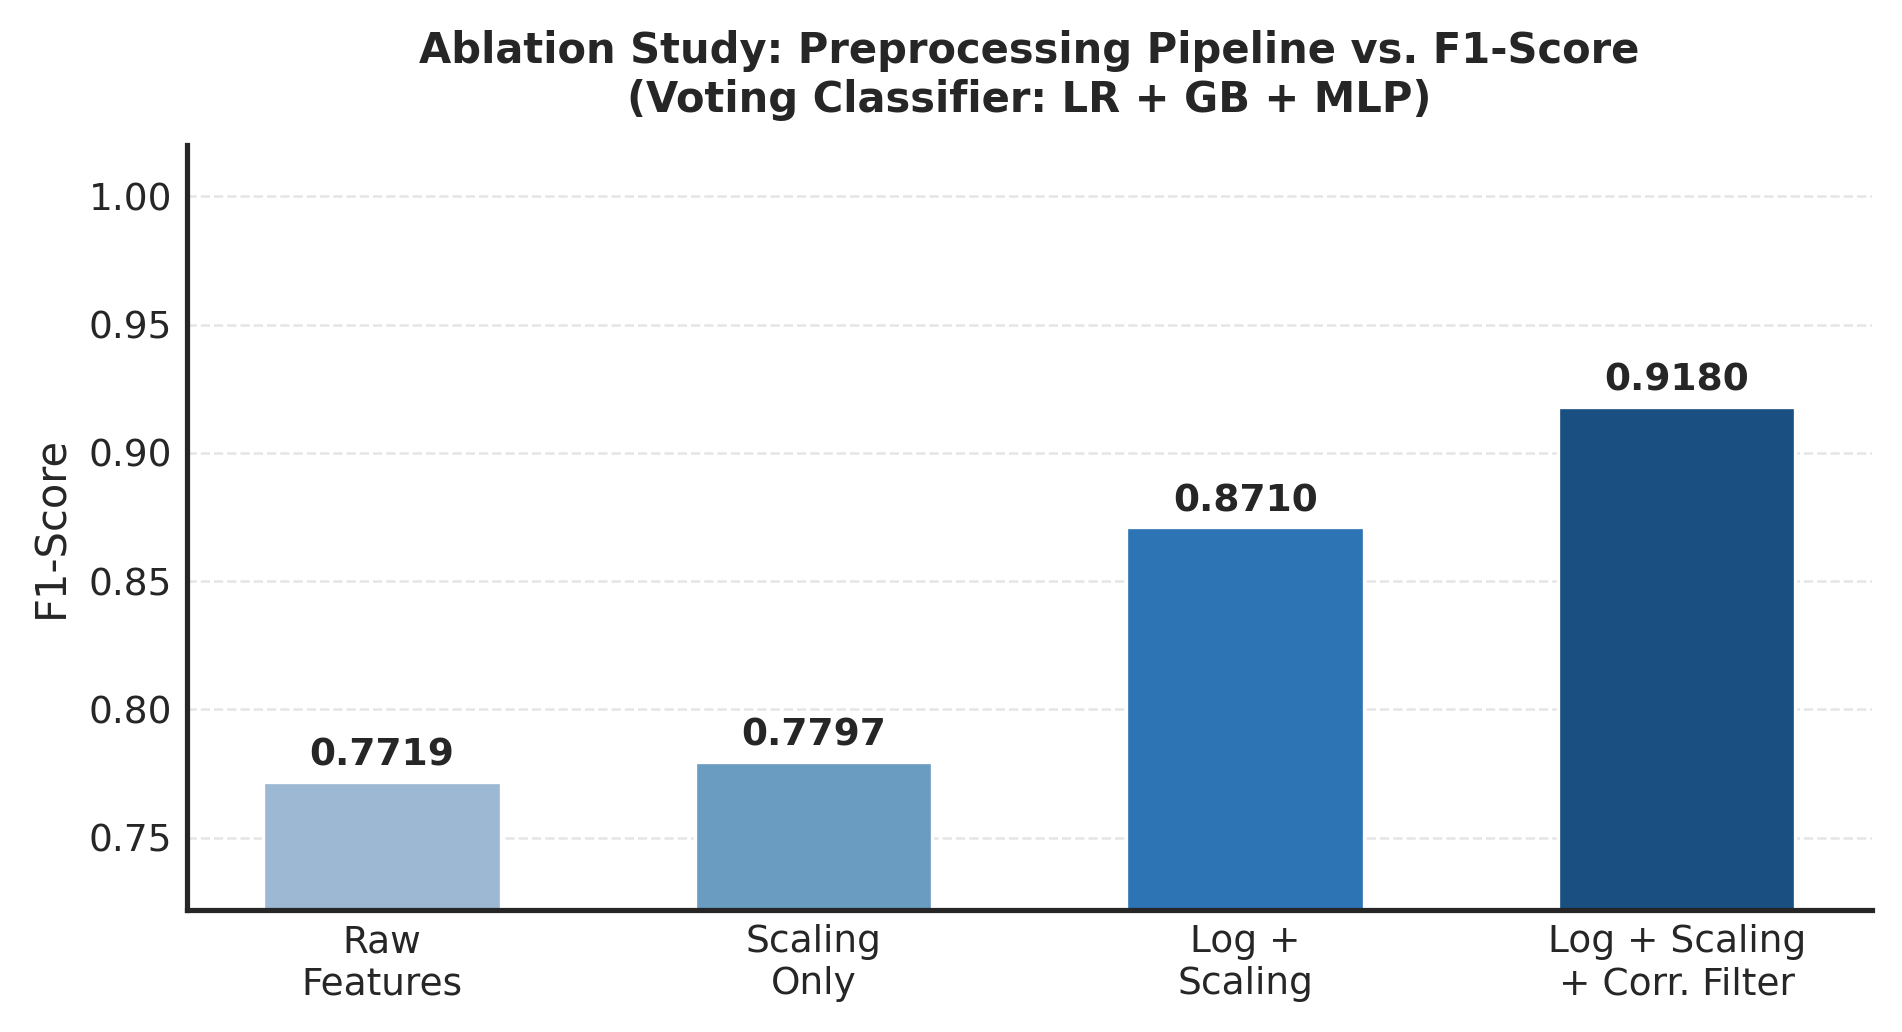

In [46]:
labels = list(ablation_results.keys())
scores = list(ablation_results.values())

short_labels = [
    "Raw\nFeatures",
    "Scaling\nOnly",
    "Log +\nScaling",
    "Log + Scaling\n+ Corr. Filter",
]

palette_ablation = ["#9db8d2", "#6a9cc2", "#2d74b5", "#1a4f82"]

fig, ax = plt.subplots(figsize=(6.5, 3.6), dpi=300)

bars = ax.bar(short_labels, scores, color=palette_ablation,
              edgecolor="white", linewidth=0.8, width=0.55)

for bar, val in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
            f"{val:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylim(min(scores) - 0.05, 1.02)
ax.set_ylabel("F1-Score", fontsize=10)
ax.set_title("Ablation Study: Preprocessing Pipeline vs. F1-Score\n(Voting Classifier: LR + GB + MLP)",
             fontsize=10, fontweight="bold", pad=8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="both", length=0, labelsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, linewidth=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("ablation_study.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

# Plots

### Radar Charts — Classifier Comparison

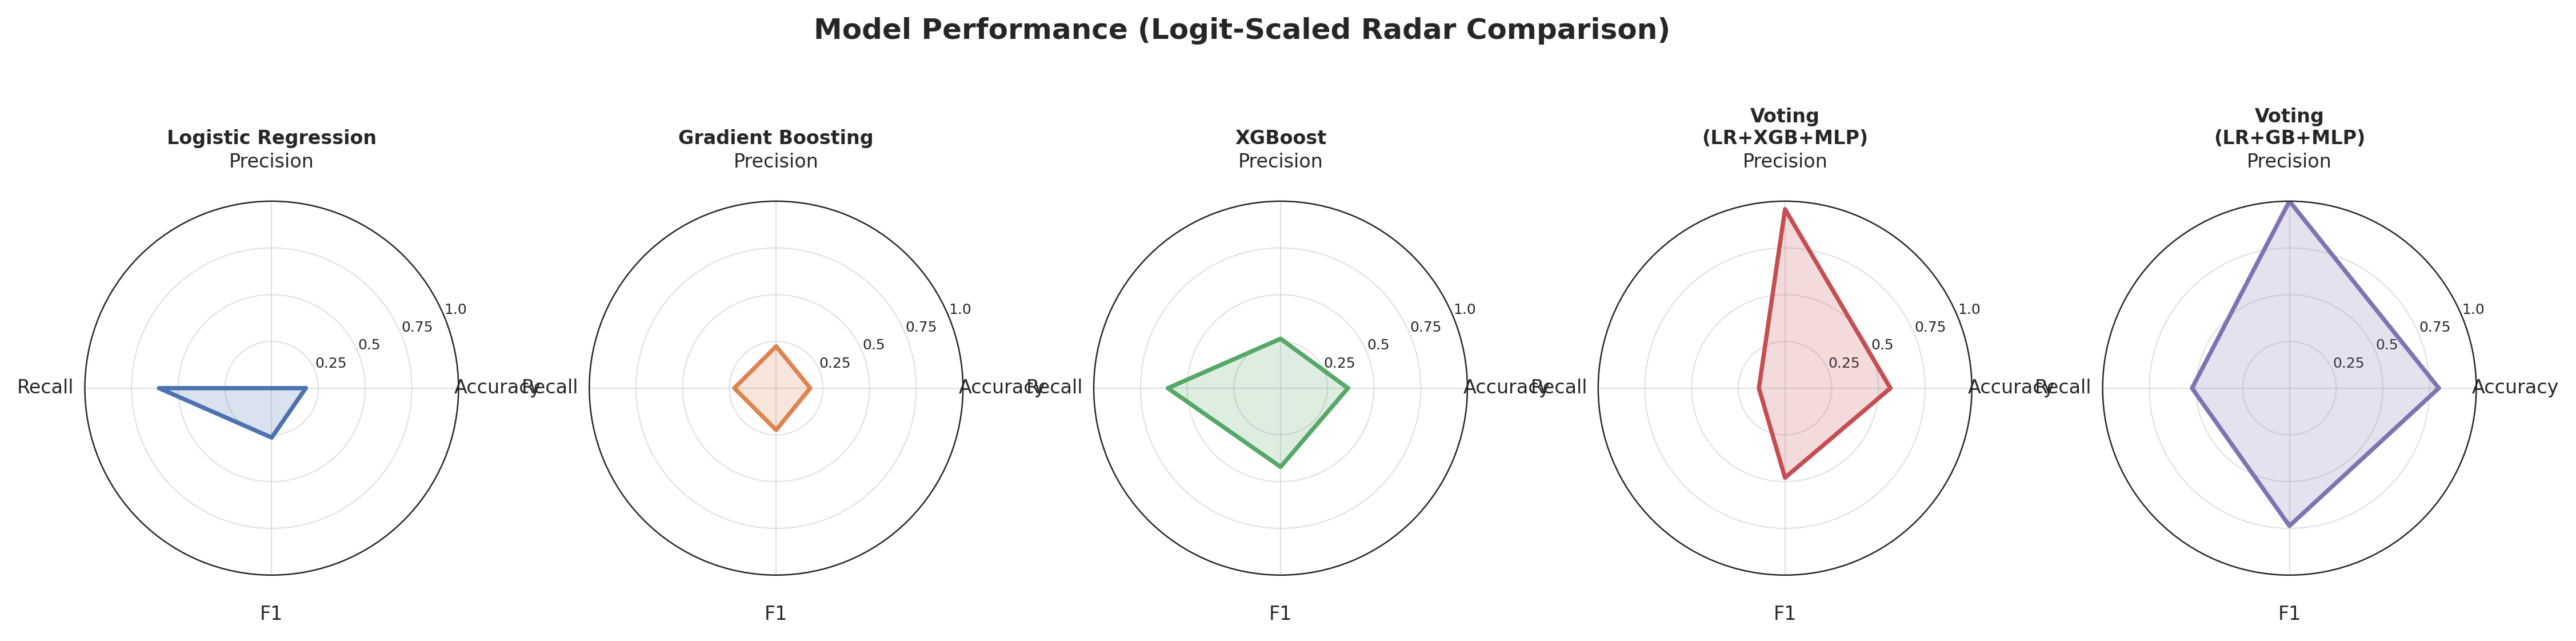

In [55]:
import numpy as np
import matplotlib.pyplot as plt

metrics_data = {
    "Logistic Regression": {
        "Accuracy": 0.8750, "Precision": 0.8571, "Recall": 0.9091, "F1": 0.8824
    },
    "Gradient Boosting": {
        "Accuracy": 0.8750, "Precision": 0.8788, "Recall": 0.8788, "F1": 0.8788
    },
    "XGBoost": {
        "Accuracy": 0.8906, "Precision": 0.8824, "Recall": 0.9091, "F1": 0.8955
    },
    "Voting (LR+XGB+MLP)": {
        "Accuracy": 0.9063, "Precision": 0.9310, "Recall": 0.8710, "F1": 0.9000
    },
    "Voting (LR+GB+MLP)": {
        "Accuracy": 0.9219, "Precision": 0.9333, "Recall": 0.9032, "F1": 0.9180
    }
}

categories = ["Accuracy", "Precision", "Recall", "F1"]

# -----------------------------
# LOGIT SCALE (IMPORTANT PART)
# -----------------------------
def logit(x):
    eps = 1e-6
    x = np.clip(x, eps, 1 - eps)
    return np.log(x / (1 - x))

all_vals = [
    logit(v[c]) for v in metrics_data.values() for c in categories
]

min_v, max_v = min(all_vals), max(all_vals)

def scale(x):
    return (logit(x) - min_v) / (max_v - min_v)

# -----------------------------
# RADAR SETUP
# -----------------------------
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]

fig, axes = plt.subplots(
    1, len(metrics_data),
    figsize=(18, 4.2),
    dpi=300,
    subplot_kw=dict(polar=True)
)

for ax, (name, scores), color in zip(axes, metrics_data.items(), palette):

    values = [scale(scores[c]) for c in categories]
    values += values[:1]

    ax.plot(angles, values, color=color, linewidth=1.8)
    ax.fill(angles, values, color=color, alpha=0.20)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=8)

    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0.25", "0.5", "0.75", "1.0"], fontsize=6)

    ax.grid(True, linewidth=0.5, alpha=0.6)
    ax.spines["polar"].set_linewidth(0.6)

    # ✅ FIX: only spacing adjustment (no structure change)
    ax.set_title(
        name.replace("Voting (", "Voting\n("),
        fontsize=8,
        fontweight="bold",
        pad=24   # keeps labels away from circle
    )

plt.subplots_adjust(top=0.82, wspace=0.35)

fig.suptitle(
    "Model Performance (Logit-Scaled Radar Comparison)",
    fontsize=12,
    fontweight="bold",
    y=0.98
)

plt.savefig("radar_final_fixed.png", dpi=300, bbox_inches="tight")
plt.show()

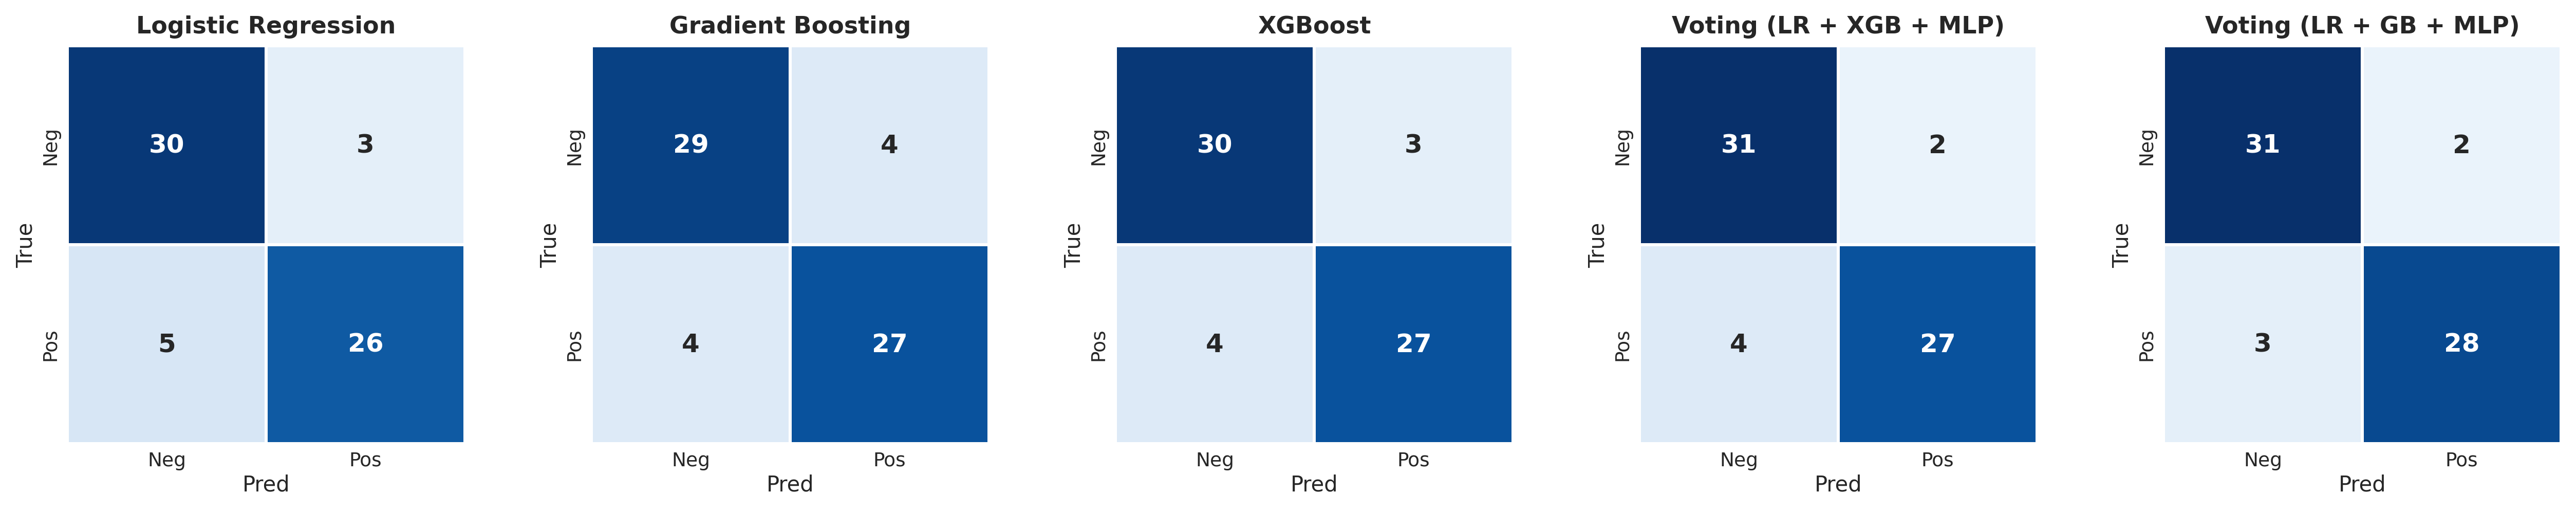

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# -----------------------------
# Confusion Matrices (SPIDER ORDER)
# -----------------------------
matrices = {
    "Logistic Regression": np.array([[30, 3],
                                    [5, 26]]),

    "Gradient Boosting": np.array([[29, 4],
                                   [4, 27]]),

    "XGBoost": np.array([[30, 3],
                         [4, 27]]),

        "Voting (LR + XGB + MLP)": np.array([[31, 2],
                                         [4, 27]]),

    "Voting (LR + GB + MLP)": np.array([[31, 2],
                                        [3, 28]])


}

# -----------------------------
# Style
# -----------------------------
sns.set_theme(style="white")

fig, axes = plt.subplots(
    1, 5,
    figsize=(17, 3.2),
    dpi=300,
    constrained_layout=True
)

vmax = max(cm.max() for cm in matrices.values())

# -----------------------------
# Plot
# -----------------------------
for ax, (title, cm) in zip(axes, matrices.items()):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        linewidths=1.0,
        linecolor="white",
        vmin=0,
        vmax=vmax,
        annot_kws={"fontsize": 12, "fontweight": "bold"},
        xticklabels=["Neg", "Pos"],
        yticklabels=["Neg", "Pos"],
        ax=ax
    )

    ax.set_title(title, fontsize=11, fontweight="bold", pad=6)
    ax.set_xlabel("Pred", fontsize=10, labelpad=2)
    ax.set_ylabel("True", fontsize=10, labelpad=2)

    ax.tick_params(axis='both', length=0, labelsize=9)

    for spine in ax.spines.values():
        spine.set_visible(False)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "confusion_matrices_spider_order.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()